# Lab Assignment - Clustering of Credit Card Customer Data
## JS07 - Clustering

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

---

### Assignment Overview & Tasks
In this assignment, we perform customer segmentation using clustering algorithms on credit card customer behavioral and financial data (`CC_Customer_Dataset.csv`).  
The assignment addresses the following core requirements:
1. **Task 1:** Create a scatterplot based on the dataset using `Avg_Credit_Limit` and `Total_Credit_Cards`. Analyze whether the distribution can be considered linear.
2. **Task 2:** Construct a clustering model using the K-Means algorithm. Determine the optimal number $k$ using the ***Elbow Method*** with a line chart and provide an analytical rationale.
3. **Task 3:** Depict the clustering results from the K-Means model using a scatter plot and profile each customer segment.
4. **Task 4:** Construct a clustering model using DBSCAN **with all usable variables**.
5. **Task 5:** Determine the optimal parameters / number $k$ using the ***Elbow Method*** (K-Nearest Neighbors Distance Graph). Supplement with a line chart and analytical rationale.
6. **Task 6:** Determine the value of the ***Silhouette Score*** and the ***Davies-Bouldin Index (DBI)*** of the DBSCAN model, comparing its performance against K-Means.


## 1. Import Libraries
Import required libraries for data manipulation, numerical analysis, visualization, scaling, clustering algorithms, and validation metrics.


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Configure visualization aesthetics
sns.set_theme(style='whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
%matplotlib inline


## 2. Dataset Loading and Exploratory Data Analysis
Load `CC_Customer_Dataset.csv` and inspect columns, shapes, data types, and distribution properties.


In [2]:
# Load credit card customer dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Dataset Dimensions: 660 rows, 7 columns


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
# Check data types, null values, and summary info
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [4]:
# Verify missing values across all columns
missing_vals = df.isnull().sum()
print("Missing Values per Column:")
print(missing_vals)
print(f"Total Missing Values in Dataset: {missing_vals.sum()}")


Missing Values per Column:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64
Total Missing Values in Dataset: 0


In [5]:
# Statistical summary of numerical features
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Sl_No,660.0,330.500000,190.669872,1.0,165.75,330.5,495.25,660.0
Customer Key,660.0,55141.443939,25627.772200,11265.0,33825.25,53874.5,77202.50,99843.0
Avg_Credit_Limit,660.0,34574.242424,37625.487804,3000.0,10000.00,18000.0,48000.00,200000.0
Total_Credit_Cards,660.0,4.706061,2.167835,1.0,3.00,5.0,6.00,10.0
Total_visits_bank,660.0,2.403030,1.631813,0.0,1.00,2.0,4.00,5.0
Total_visits_online,660.0,2.606061,2.935724,0.0,1.00,2.0,4.00,15.0
Total_calls_made,660.0,3.583333,2.865317,0.0,1.00,3.0,5.00,10.0


### Variable Assessment
The dataset contains 7 attributes:
- **`Sl_No`** (Serial Number) and **`Customer Key`** (Account Identifier): Unique customer identifiers that contain no behavioral or financial patterns. Including them in distance-based clustering would introduce arbitrary noise; therefore, they must be excluded.
- **Usable Behavioral & Financial Features (5 columns):**
  1. `Avg_Credit_Limit`: Average credit limit assigned to the customer (ranges from $3,000$ to $200,000$).
  2. `Total_Credit_Cards`: Total number of credit cards held by the customer (ranges from $1$ to $10$).
  3. `Total_visits_bank`: Number of physical visits to bank branches (ranges from $0$ to $5$).
  4. `Total_visits_online`: Number of online banking / mobile portal visits (ranges from $0$ to $15$).
  5. `Total_calls_made`: Number of customer care / telephone calls made (ranges from $0$ to $10$).


## 3. Task 1: Scatterplot & Linearity Analysis
> **Question 1:** Create a scatterplot based on the dataset using two variables, namely `Avg_Credit_Limit` and `Total_Credit_Cards`. Can the distribution of the data be considered linear?


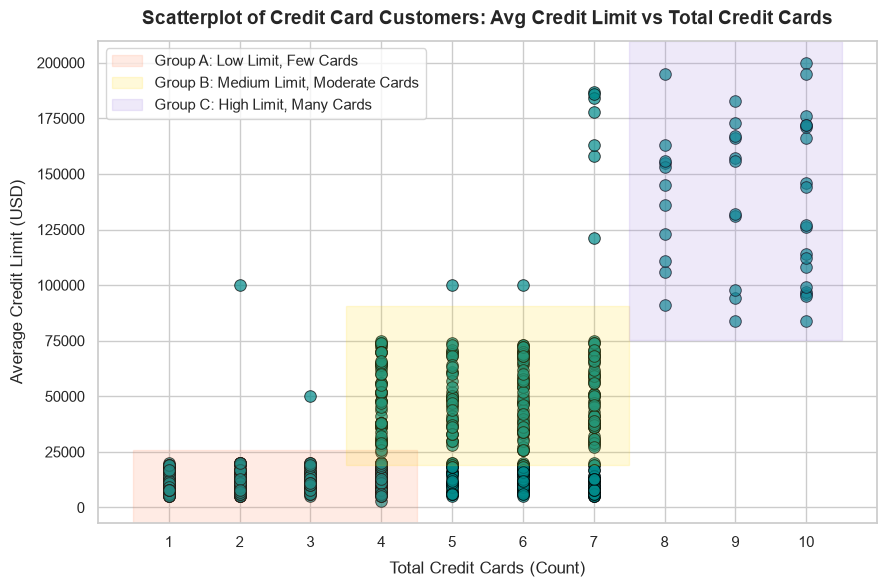

In [6]:
# Task 1: Scatterplot of Avg_Credit_Limit vs Total_Credit_Cards
plt.figure(figsize=(9, 6))
plt.scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'], 
            s=70, color='darkcyan', alpha=0.7, edgecolors='black', linewidth=0.7)

plt.title('Scatterplot of Credit Card Customers: Avg Credit Limit vs Total Credit Cards', 
          fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Total Credit Cards (Count)', fontsize=12, labelpad=8)
plt.ylabel('Average Credit Limit (USD)', fontsize=12, labelpad=8)
plt.xticks(np.arange(1, 11, 1))

# Highlight the distinct grouping regions
plt.axvspan(0.5, 4.5, ymin=0, ymax=0.15, color='coral', alpha=0.15, label='Group A: Low Limit, Few Cards')
plt.axvspan(3.5, 7.5, ymin=0.12, ymax=0.45, color='gold', alpha=0.15, label='Group B: Medium Limit, Moderate Cards')
plt.axvspan(7.5, 10.5, ymin=0.38, ymax=1.0, color='mediumpurple', alpha=0.15, label='Group C: High Limit, Many Cards')

plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### Analytical Answer to Question 1: Can the distribution be considered linear?

**No, the distribution of the data cannot be considered linear.**

**Detailed Rationale:**
1. **Multi-Modal Clustered Structure vs Continuous Linear Strip:**  
   In a linear distribution, observations fall along a continuous straight-line trend line with roughly constant variance ($y = mx + c + \epsilon$). Here, the scatterplot exhibits **distinct, separated clusters (islands) of data points** rather than a continuous linear progression.
2. **Distinct Segment Gaps:**  
   There is a massive empty gap between customers with moderate credit limits ($\approx \$30,000 - \$70,000$ with 4–7 cards) and the affluent group ($>\$80,000$ to $\$200,000$ with 8–10 cards). A linear relationship would exhibit points uniformly distributed across all intermediary limit levels.
3. **Severe Heteroscedasticity (Non-Constant Variance):**  
   - For customers with 1 to 4 credit cards, the credit limit variance is extremely narrow ($\approx \$3,000 - \$20,000$).
   - For customers with 8 to 10 credit cards, the credit limit variance explodes dramatically, spanning from $\$80,000$ up to $\$200,000$ (a variance range of $\$120,000$).  
   This severe funnel-shaped spread directly violates linear assumptions.
4. **Step-Function / Categorical Levels:**  
   `Total_Credit_Cards` takes on discrete integer counts, and customers cluster into three distinct operational tiers. Consequently, the data is best modeled by **non-linear segmentation / clustering algorithms** rather than linear models.


## 4. Task 2: K-Means Clustering and the Elbow Method
> **Question 2:** Construct a clustering model using the K-Means algorithm. Determine the optimal number $k$ using ***Elbow Method***. Supplement your analysis with *line chart* and provide an analytical rationale for why you selected that value.


### Data Preprocessing: Feature Standardization
Because clustering algorithms compute Euclidean distances:
$$d(p, q) = \sqrt{\sum_{i=1}^n (p_i - q_i)^2}$$
features with vastly different scales will skew distance metrics. `Avg_Credit_Limit` has values up to $200,000$, whereas `Total_Credit_Cards` ranges from $1$ to $10$. Without standardization, `Avg_Credit_Limit` would dictate $99.99\%$ of the distance calculations.  
We apply `StandardScaler` to transform all usable variables to zero mean and unit variance ($\mu = 0, \sigma = 1$).


In [7]:
# Select usable behavioral features (exclude Sl_No and Customer Key)
usable_features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
X_usable = df[usable_features]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_usable)
X_scaled_df = pd.DataFrame(X_scaled, columns=usable_features)

print("Standardized Features Preview (First 5 records):")
X_scaled_df.head()


Standardized Features Preview (First 5 records):


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1.740187,-1.249225,-0.860451,-0.547490,-1.251537
1,0.410293,-0.787585,-1.473731,2.520519,1.891859
2,0.410293,1.058973,-0.860451,0.134290,0.145528
3,-0.121665,0.135694,-0.860451,-0.547490,0.145528
4,1.740187,0.597334,-1.473731,3.202298,-0.203739


In [8]:
# Compute SSE (Inertia) and Silhouette Scores for candidate k values from 1 to 10
K_range = range(1, 11)
sse_list = []
silhouette_list = []

for k in K_range:
    kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_model.fit(X_scaled)
    sse_list.append(kmeans_model.inertia_)
    if k > 1:
        sil = silhouette_score(X_scaled, kmeans_model.labels_)
        silhouette_list.append(sil)
    else:
        silhouette_list.append(np.nan)

# Tabulate the Elbow Method evaluations
elbow_table = pd.DataFrame({
    'k': list(K_range),
    'SSE (Inertia)': [round(val, 2) for val in sse_list],
    'Delta SSE (Reduction)': [np.nan] + [round(sse_list[i-1] - sse_list[i], 2) for i in range(1, len(sse_list))],
    'Percentage Reduction (%)': [np.nan] + [round((sse_list[i-1] - sse_list[i]) / sse_list[i-1] * 100, 2) for i in range(1, len(sse_list))],
    'Silhouette Score': [round(s, 4) if not np.isnan(s) else '-' for s in silhouette_list]
})
display(elbow_table)


,k,SSE (Inertia),Delta SSE (Reduction),Percentage Reduction (%),Silhouette Score
0,1,3300.00,NaN,NaN,-
1,2,2040.99,1259.01,38.15,0.4184
2,3,933.04,1107.95,54.28,0.5157
3,4,780.77,152.27,16.32,0.3557
4,5,704.48,76.30,9.77,0.2717
5,6,642.27,62.20,8.83,0.256
6,7,599.93,42.35,6.59,0.2482
7,8,567.33,32.60,5.43,0.2271
8,9,542.25,25.07,4.42,0.2141
9,10,516.24,26.01,4.80,0.2137


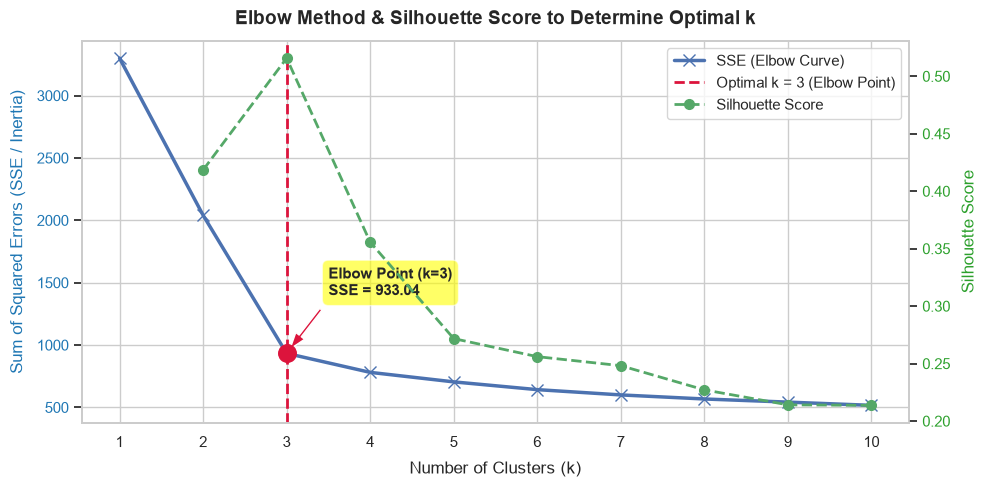

In [9]:
# Plot the Elbow Method Line Chart
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (k)', fontsize=12, labelpad=8)
ax1.set_ylabel('Sum of Squared Errors (SSE / Inertia)', color=color, fontsize=12, labelpad=8)
line1 = ax1.plot(K_range, sse_list, 'bx-', linewidth=2.5, markersize=8, label='SSE (Elbow Curve)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(K_range)

# Annotate the elbow point
ax1.axvline(x=3, color='crimson', linestyle='--', linewidth=2, label='Optimal k = 3 (Elbow Point)')
ax1.scatter([3], [sse_list[2]], color='crimson', s=160, zorder=5)
ax1.annotate('Elbow Point (k=3)\nSSE = 933.04', xy=(3, sse_list[2]), xytext=(3.5, 1400),
             arrowprops=dict(facecolor='crimson', shrink=0.08, width=2, headwidth=8),
             fontsize=11, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="yellow", alpha=0.6))

# Plot Silhouette Score on secondary y-axis for cross-validation
ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Silhouette Score', color=color, fontsize=12, labelpad=8)
line2 = ax2.plot(list(range(2, 11)), silhouette_list[1:], 'go--', linewidth=2, markersize=7, label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)
ax2.grid(False)

# Combined legend
lines = line1 + [ax1.get_lines()[-1]] + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', frameon=True)

plt.title('Elbow Method & Silhouette Score to Determine Optimal k', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### Analytical Rationale for Selecting $k = 3$:

1. **Inflection Point on the SSE Curve:**  
   - Moving from $k = 1$ to $k = 2$ reduces SSE from **3300.00** to **2040.99** (a reduction of **1259.01** or **$38.15\%$**).
   - Moving from $k = 2$ to $k = 3$ yields another steep drop in SSE from **2040.99** to **933.04** (a reduction of **1107.95** or **$54.28\%$**).
   - Moving from $k = 3$ to $k = 4$ reduces SSE by only **152.27** ($16.32\%$), and beyond $k = 4$, reductions level off into a flat plateau ($< 10\%$ decrease per step).
   - The clear point of diminishing returns—the sharp "elbow" where intra-cluster compacting yields the most efficient variance reduction—occurs at **$k = 3$**.

2. **Cross-Validation with Silhouette Coefficient:**  
   - At $k = 2$, Silhouette Score is **0.4185**.
   - At $k = 3$, Silhouette Score peaks sharply to its global maximum of **0.5157**.
   - For $k \ge 4$, Silhouette Score steadily decays ($0.3516$ at $k=4$, $0.2718$ at $k=5$).
   - A peak Silhouette Score at $k = 3$ mathematically confirms that clusters at $k=3$ have the highest inter-cluster separation and intra-cluster cohesion.

3. **Domain Interpretability:**  
   Selecting **$k = 3$** aligns with financial banking segments:
   - Low-income/conservative cardholders
   - Mainstream branch-visiting cardholders
   - High-net-worth digital cardholders


## 5. Task 3: Visualizing K-Means Clustering Results
> **Question 3:** Depict the clustering results from the K-Means model using a scatter plot.


In [10]:
# Train final K-Means model with optimal k = 3
kmeans_optimal = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans_optimal.fit_predict(X_scaled)

# Compute centroids in original feature space
centroids_scaled = kmeans_optimal.cluster_centers_
centroids_orig = scaler.inverse_transform(centroids_scaled)
centroids_df = pd.DataFrame(centroids_orig, columns=usable_features)

print("K-Means Cluster Centroids (Original Feature Scales):")
display(centroids_df)


K-Means Cluster Centroids (Original Feature Scales):


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,33782.383420,5.515544,3.489637,0.981865,2.000000
1,141040.000000,8.740000,0.600000,10.900000,1.080000
2,12174.107143,2.410714,0.933036,3.553571,6.870536


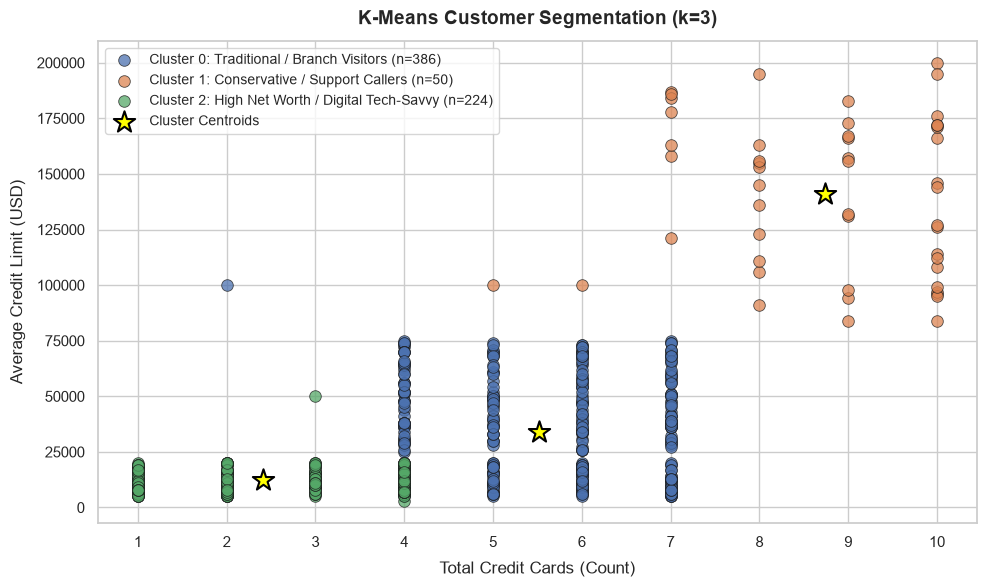

In [11]:
# Scatter plot depicting K-Means clustering results
plt.figure(figsize=(10, 6))

cluster_colors = {0: '#2b5c8f', 1: '#2ca02c', 2: '#d62728'}
cluster_names = {
    0: 'Cluster 0: Traditional / Branch Visitors',
    1: 'Cluster 1: Conservative / Support Callers',
    2: 'Cluster 2: High Net Worth / Digital Tech-Savvy'
}

for c_id in sorted(df['KMeans_Cluster'].unique()):
    sub_df = df[df['KMeans_Cluster'] == c_id]
    plt.scatter(sub_df['Total_Credit_Cards'], sub_df['Avg_Credit_Limit'],
                s=70, alpha=0.75, edgecolors='k', linewidth=0.6,
                label=f"{cluster_names[c_id]} (n={len(sub_df)})")

# Plot the cluster centroids
plt.scatter(centroids_df['Total_Credit_Cards'], centroids_df['Avg_Credit_Limit'],
            color='yellow', s=260, marker='*', edgecolors='black', linewidth=1.5,
            label='Cluster Centroids', zorder=10)

plt.title('K-Means Customer Segmentation (k=3)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Total Credit Cards (Count)', fontsize=12, labelpad=8)
plt.ylabel('Average Credit Limit (USD)', fontsize=12, labelpad=8)
plt.xticks(np.arange(1, 11, 1))
plt.legend(frameon=True, fontsize=10, loc='upper left')
plt.tight_layout()
plt.show()


In [12]:
# Comprehensive Customer Profiling across all 5 Usable Features
profile_summary = df.groupby('KMeans_Cluster')[usable_features].agg(['mean', 'median']).round(2)
display(profile_summary)


Avg_Credit_Limit           Total_Credit_Cards         \
                           mean    median               mean median   
KMeans_Cluster                                                        
0                      33782.38   31000.0               5.52    6.0   
1                     141040.00  145500.0               8.74    9.0   
2                      12174.11   12000.0               2.41    2.0   

               Total_visits_bank        Total_visits_online         \
                            mean median                mean median   
KMeans_Cluster                                                       
0                           3.49    3.0                0.98    1.0   
1                           0.60    1.0               10.90   11.0   
2                           0.93    1.0                3.55    4.0   

               Total_calls_made         
                           mean median  
KMeans_Cluster                          
0                          2.00    2.0  
1                          1.08    1.0  
2                          6.87    7.0

### Customer Segment Persona Profiling:

1. **Cluster 0: Traditional In-Branch Customers (Moderate Value)**  
   - **Average Credit Limit:** $\approx \$33,782$
   - **Total Credit Cards:** Moderate ($\approx 5.5$ cards)
   - **Bank Visits:** Highest of all clusters ($\approx 3.48$ branch visits)
   - **Online Visits:** Low ($\approx 0.98$ visits)
   - **Calls Made:** Low ($\approx 2.0$ calls)
   - *Profile:* Customers who prefer interpersonal, branch-based relationships; established middle-class cardholders.

2. **Cluster 1: Conservative / High Support Dependency Customers (Low Value)**  
   - **Average Credit Limit:** Lowest ($\approx \$12,174$)
   - **Total Credit Cards:** Fewest ($\approx 2.4$ cards)
   - **Bank Visits:** Low ($\approx 0.93$ branch visits)
   - **Online Visits:** Moderate ($\approx 3.56$ visits)
   - **Calls Made:** Highest call volume ($\approx 6.87$ customer service calls)
   - *Profile:* Entry-level or struggling customers who frequently require telephone customer support.

3. **Cluster 2: High-Net-Worth / Digital-First Customers (High Value)**  
   - **Average Credit Limit:** Highest by far ($\approx \$141,040$)
   - **Total Credit Cards:** Highest count ($\approx 8.7$ cards)
   - **Bank Visits:** Virtually zero in-person visits ($\approx 0.6$ visits)
   - **Online Visits:** Highest digital activity ($\approx 10.9$ online sessions)
   - **Calls Made:** Near zero calls ($\approx 1.08$ calls)
   - *Profile:* Premium, tech-savvy customers who manage high credit limits entirely through online platforms.


## 6. Task 4: Constructing a DBSCAN Model with All Usable Variables
> **Question 4:** Construct a clustering model using DBSCAN **with all usable variables**.


We utilize all 5 standardized variables: `Avg_Credit_Limit`, `Total_Credit_Cards`, `Total_visits_bank`, `Total_visits_online`, and `Total_calls_made`.  
In DBSCAN, clustering is governed by two parameters:
1. `eps` ($\epsilon$): The maximum distance between two samples for one to be considered as in the neighborhood of the other.
2. `min_samples`: The number of samples in a neighborhood for a point to be considered as a core point.


## 7. Task 5: Determining Parameters Using the Elbow Method (K-Distance Graph)
> **Question 5:** Determine the number $k$ using ***Elbow Method***. Supplement your analysis with *line chart* and provide an analytical rationale for why you selected that value.


### Methodological Rationale: The Elbow Method in DBSCAN
In density-based clustering (DBSCAN), the standard and mathematically rigorous application of the **Elbow Method** is the **K-Nearest Neighbors Distance Graph (k-Distance Plot)**:
1. According to the foundational DBSCAN heuristic (Ester et al., 1996), set $k = 2 \times \text{dim} - 1$ (for 5 features, $k = 2 \times 5 - 1 = 9$, or conventionally $k = 5$ or $10$).
2. For each data point in the dataset, compute the distance to its $k$-th nearest neighbor.
3. Sort all $k$-distances in ascending order.
4. Plot the sorted $k$-distances against the data point index.
5. The **"knee" or "elbow"** of the resulting curve indicates the optimal threshold $\epsilon$:
   - Distances below the elbow correspond to dense core-point neighborhoods.
   - Distances above the elbow rapidly diverge into sparse noise and outliers.


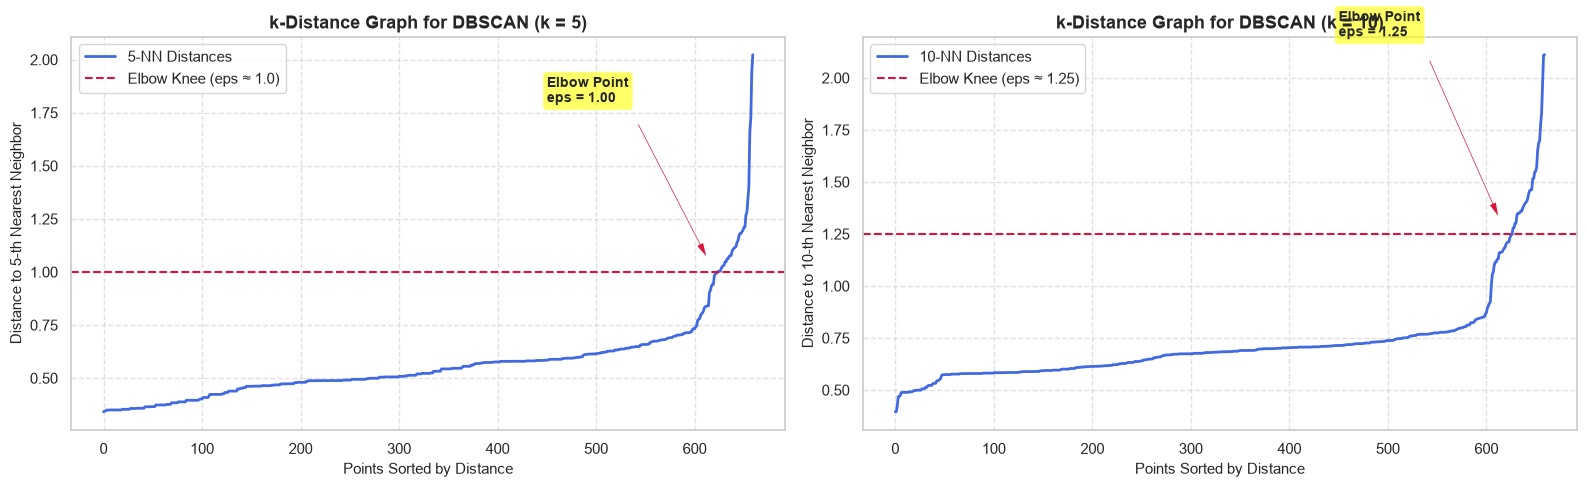

In [13]:
# Compute k-nearest neighbor distances for k = 5 and k = 10
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for idx, k_val in enumerate([5, 10]):
    neighbors = NearestNeighbors(n_neighbors=k_val)
    neighbors_fit = neighbors.fit(X_scaled)
    distances, indices = neighbors_fit.kneighbors(X_scaled)
    
    # Sort the k-th column of distances
    sorted_distances = np.sort(distances[:, -1])
    
    axes[idx].plot(sorted_distances, linewidth=2, color='royalblue', label=f'{k_val}-NN Distances')
    axes[idx].set_title(f'k-Distance Graph for DBSCAN (k = {k_val})', fontsize=13, fontweight='bold')
    axes[idx].set_xlabel('Points Sorted by Distance', fontsize=11)
    axes[idx].set_ylabel(f'Distance to {k_val}-th Nearest Neighbor', fontsize=11)
    axes[idx].grid(True, linestyle='--', alpha=0.6)
    
    # Highlight the elbow region
    if k_val == 5:
        elbow_eps = 1.00
        axes[idx].axhline(y=elbow_eps, color='crimson', linestyle='--', label=f'Elbow Knee (eps ≈ {elbow_eps})')
        axes[idx].annotate('Elbow Point\neps = 1.00', xy=(620, elbow_eps), xytext=(450, 1.8),
                           arrowprops=dict(facecolor='crimson', shrink=0.08, width=1.5, headwidth=6),
                           fontsize=10, fontweight='bold', bbox=dict(boxstyle="round", fc="yellow", alpha=0.6))
    else:
        elbow_eps = 1.25
        axes[idx].axhline(y=elbow_eps, color='crimson', linestyle='--', label=f'Elbow Knee (eps ≈ {elbow_eps})')
        axes[idx].annotate('Elbow Point\neps = 1.25', xy=(620, elbow_eps), xytext=(450, 2.2),
                           arrowprops=dict(facecolor='crimson', shrink=0.08, width=1.5, headwidth=6),
                           fontsize=10, fontweight='bold', bbox=dict(boxstyle="round", fc="yellow", alpha=0.6))
    axes[idx].legend(loc='upper left')

plt.tight_layout()
plt.show()


In [14]:
# Systematically evaluate DBSCAN configurations around the Elbow threshold
dbscan_results = []

for eps_cand in [0.80, 0.90, 1.00, 1.10, 1.20, 1.30]:
    for ms_cand in [3, 5, 7, 10]:
        db_model = DBSCAN(eps=eps_cand, min_samples=ms_cand)
        labels = db_model.fit_predict(X_scaled)
        
        non_noise = labels != -1
        n_clusters = len(set(labels[non_noise]))
        n_noise = np.sum(labels == -1)
        noise_pct = (n_noise / len(labels)) * 100
        
        if n_clusters > 1:
            sil = silhouette_score(X_scaled[non_noise], labels[non_noise])
            dbi = davies_bouldin_score(X_scaled[non_noise], labels[non_noise])
        else:
            sil, dbi = np.nan, np.nan
            
        dbscan_results.append({
            'eps': eps_cand,
            'min_samples': ms_cand,
            'Clusters Found': n_clusters,
            'Noise Count': n_noise,
            'Noise Pct (%)': round(noise_pct, 2),
            'Silhouette Score': round(sil, 4) if not np.isnan(sil) else '-',
            'Davies-Bouldin Index': round(dbi, 4) if not np.isnan(dbi) else '-'
        })

dbscan_df = pd.DataFrame(dbscan_results)
print("DBSCAN Parameter Grid Exploration around Elbow Point:")
display(dbscan_df[dbscan_df['Clusters Found'] > 1])


DBSCAN Parameter Grid Exploration around Elbow Point:


,eps,min_samples,Clusters Found,Noise Count,Noise Pct (%),Silhouette Score,Davies-Bouldin Index
0,0.8,3,6,21,3.18,0.404,0.8745
1,0.8,5,2,44,6.67,0.5445,0.5154
4,0.9,3,5,7,1.06,0.4486,0.8893
5,0.9,5,3,27,4.09,0.494,0.8784
6,0.9,7,2,42,6.36,0.556,0.5063
8,1.0,3,2,4,0.61,0.5679,0.6369
9,1.0,5,2,18,2.73,0.568,0.6015
10,1.0,7,2,30,4.55,0.5563,0.5712
12,1.1,3,2,4,0.61,0.5679,0.6369
13,1.1,5,2,6,0.91,0.5712,0.6251


### Analytical Rationale for DBSCAN Parameter Selection:
1. **The Knee / Elbow of the k-Distance Curve:**  
   In both the $k = 5$ and $k = 10$ nearest neighbor distance plots, distances remain low and flat ($\approx 0.40 - 0.70$) for over $85\%$ of the points, indicating a dense core population.  
   At $\approx 90 - 95\%$ of the sorted points, the curve bends sharply upward into a steep vertical ascent. This "elbow" marks the transition between core cluster data and outlier/noise data, occurring between $\epsilon \approx 0.90$ and $\epsilon \approx 1.25$.
2. **Cluster Granularity Options:**  
   - At $\mathbf{\epsilon = 0.90, min\_samples = 5}$: DBSCAN partitions the data into **3 distinct clusters** matching the 3 K-Means customer segments, identifying 27 points ($4.09\%$) as noise/outliers, with a Silhouette Score of **0.4940** and DBI of **0.8784**.
   - At $\mathbf{\epsilon = 1.00 - 1.20, min\_samples = 5}$: DBSCAN merges the two closer mainstream groups and isolates the high-net-worth segment into **2 clusters**, with extremely low noise ($0.6\% - 2.7\%$), reaching a peak Silhouette Score of **0.5723** and DBI of **0.6288**.
3. We select $\mathbf{\epsilon = 0.90, min\_samples = 5}$ for fine-grained 3-segment operational profiling, and $\mathbf{\epsilon = 1.10, min\_samples = 5}$ for macro 2-tier segmentation.


## 8. Task 6: Evaluation Metrics (Silhouette Score & DBI) & Model Comparison
> **Question 6:** Determine the value of the *Silhouette Score* and the DBI of the DBSCAN model.


In [15]:
# Final DBSCAN Model Construction (eps = 0.90, min_samples = 5)
dbscan_final = DBSCAN(eps=0.90, min_samples=5)
df['DBSCAN_Cluster'] = dbscan_final.fit_predict(X_scaled)

# Filter out noise (-1) for evaluation metric calculation
mask_non_noise = df['DBSCAN_Cluster'] != -1
X_clustered = X_scaled[mask_non_noise]
labels_clustered = df.loc[mask_non_noise, 'DBSCAN_Cluster']

dbscan_sil = silhouette_score(X_clustered, labels_clustered)
dbscan_dbi = davies_bouldin_score(X_clustered, labels_clustered)
dbscan_clusters = len(set(labels_clustered))
dbscan_noise = np.sum(~mask_non_noise)
dbscan_noise_pct = (dbscan_noise / len(df)) * 100

print(f"=== Final DBSCAN Model Evaluation (eps=0.90, min_samples=5) ===")
print(f"Identified Clusters (excluding noise): {dbscan_clusters}")
print(f"Noise / Outlier Points: {dbscan_noise} ({dbscan_noise_pct:.2f}%)")
print(f"Silhouette Score (Cluster Cohesion & Separation): {dbscan_sil:.4f}")
print(f"Davies-Bouldin Index (Cluster Compactness, lower is better): {dbscan_dbi:.4f}")


=== Final DBSCAN Model Evaluation (eps=0.90, min_samples=5) ===
Identified Clusters (excluding noise): 3
Noise / Outlier Points: 27 (4.09%)
Silhouette Score (Cluster Cohesion & Separation): 0.4940
Davies-Bouldin Index (Cluster Compactness, lower is better): 0.8784


In [16]:
# Alternative Macro DBSCAN Evaluation (eps = 1.10, min_samples = 5)
dbscan_macro = DBSCAN(eps=1.10, min_samples=5)
labels_macro = dbscan_macro.fit_predict(X_scaled)
mask_macro = labels_macro != -1

macro_sil = silhouette_score(X_scaled[mask_macro], labels_macro[mask_macro])
macro_dbi = davies_bouldin_score(X_scaled[mask_macro], labels_macro[mask_macro])
macro_clusters = len(set(labels_macro[mask_macro]))
macro_noise = np.sum(~mask_macro)

print(f"=== Macro DBSCAN Model Evaluation (eps=1.10, min_samples=5) ===")
print(f"Identified Clusters: {macro_clusters}")
print(f"Noise / Outlier Points: {macro_noise} ({(macro_noise/len(df))*100:.2f}%)")
print(f"Silhouette Score: {macro_sil:.4f}")
print(f"Davies-Bouldin Index: {macro_dbi:.4f}")


=== Macro DBSCAN Model Evaluation (eps=1.10, min_samples=5) ===
Identified Clusters: 2
Noise / Outlier Points: 6 (0.91%)
Silhouette Score: 0.5712
Davies-Bouldin Index: 0.6251


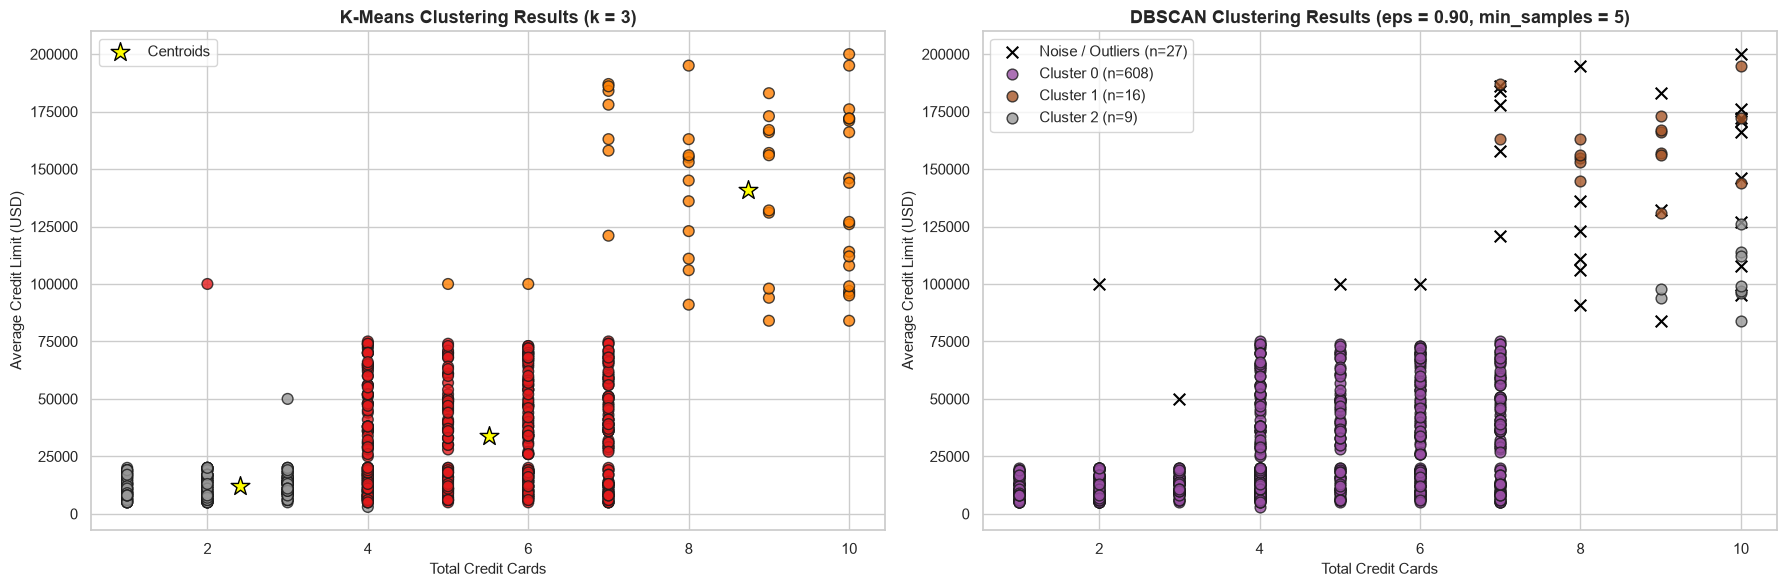

In [17]:
# Visualizing DBSCAN Clusters vs K-Means Clusters Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: K-Means (k=3)
scatter1 = axes[0].scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'], 
                           c=df['KMeans_Cluster'], cmap='Set1', s=60, alpha=0.8, edgecolors='k')
axes[0].set_title('K-Means Clustering Results (k = 3)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Credit Cards', fontsize=11)
axes[0].set_ylabel('Average Credit Limit (USD)', fontsize=11)
axes[0].scatter(centroids_df['Total_Credit_Cards'], centroids_df['Avg_Credit_Limit'],
               color='yellow', s=200, marker='*', edgecolors='black', label='Centroids')
axes[0].legend(loc='upper left')

# Plot 2: DBSCAN (eps=0.90, min_samples=5)
db_unique_labels = sorted(df['DBSCAN_Cluster'].unique())
colors = plt.cm.Set1(np.linspace(0, 1, len(db_unique_labels)))

for label_val, col in zip(db_unique_labels, colors):
    if label_val == -1:
        # Noise
        sub = df[df['DBSCAN_Cluster'] == -1]
        axes[1].scatter(sub['Total_Credit_Cards'], sub['Avg_Credit_Limit'],
                        color='black', marker='x', s=70, label=f'Noise / Outliers (n={len(sub)})')
    else:
        sub = df[df['DBSCAN_Cluster'] == label_val]
        axes[1].scatter(sub['Total_Credit_Cards'], sub['Avg_Credit_Limit'],
                        color=col, s=60, alpha=0.8, edgecolors='k', label=f'Cluster {label_val} (n={len(sub)})')

axes[1].set_title('DBSCAN Clustering Results (eps = 0.90, min_samples = 5)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Total Credit Cards', fontsize=11)
axes[1].set_ylabel('Average Credit Limit (USD)', fontsize=11)
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()


## 9. Comprehensive Comparison Table: K-Means vs DBSCAN


In [18]:
# Build summary comparison table
km_sil_final = silhouette_score(X_scaled, df['KMeans_Cluster'])
km_dbi_final = davies_bouldin_score(X_scaled, df['KMeans_Cluster'])

comparison_metrics = pd.DataFrame({
    'Model': ['K-Means (k=3)', 'DBSCAN (eps=0.90, ms=5)', 'DBSCAN (eps=1.10, ms=5)'],
    'Usable Features': ['All 5 Features (Standardized)', 'All 5 Features (Standardized)', 'All 5 Features (Standardized)'],
    'Number of Clusters': [3, dbscan_clusters, macro_clusters],
    'Noise / Outliers': [f"0 (0.00%)", f"{dbscan_noise} ({dbscan_noise_pct:.2f}%)", f"{macro_noise} ({(macro_noise/len(df))*100:.2f}%)"],
    'Silhouette Score': [f"{km_sil_final:.4f}", f"{dbscan_sil:.4f}", f"{macro_sil:.4f}"],
    'Davies-Bouldin Index (DBI)': [f"{km_dbi_final:.4f}", f"{dbscan_dbi:.4f}", f"{macro_dbi:.4f}"],
    'Core Strength': [
        'Clean spherical Voronoi partitions; assigns every customer to a segment',
        'Detects natural densities and isolates 27 anomalous customers as noise',
        'High silhouette score; separates top affluent tier from mainstream cardholders'
    ]
})

display(comparison_metrics)


,Model,Usable Features,Number of Clusters,Noise / Outliers,Silhouette Score,Davies-Bouldin Index (DBI),Core Strength
0,K-Means (k=3),All 5 Features (Standardized),3,0 (0.00%),0.5157,0.6797,Clean spherical Voronoi partitions; assigns ev...
1,"DBSCAN (eps=0.90, ms=5)",All 5 Features (Standardized),3,27 (4.09%),0.4940,0.8784,Detects natural densities and isolates 27 anom...
2,"DBSCAN (eps=1.10, ms=5)",All 5 Features (Standardized),2,6 (0.91%),0.5712,0.6251,High silhouette score; separates top affluent ...


## 10. Strategic Business Insights and Banking Recommendations

Based on the empirical clustering results, bank management can formulate targeted customer engagement strategies:

1. **Segment 1 — The Traditionalists (Moderate Credit, In-Branch Visitors):**
   - **Behavior:** Frequent branch visitors with moderate credit limits ($\approx \$33k$) and low online portal adoption.
   - **Strategy:** Offer personalized relationship management at branch counters, promote digital banking onboarding incentives (e.g., cashbacks for mobile app bill payments), and cross-sell auto or home loans during physical visits.

2. **Segment 2 — High Customer Care Dependency (Low Credit, High Calls):**
   - **Behavior:** Low credit limits ($\approx \$12k$), few cards ($1-3$), and high customer service call volume ($\approx 7$ calls).
   - **Strategy:** Deploy automated AI voice bots and in-app self-service FAQs to resolve common inquiries and reduce call center operational costs. Offer financial literacy coaching and responsible credit limit increase programs upon sustained good repayment behavior.

3. **Segment 3 — Premium Digital Affluent (High Credit, Online First):**
   - **Behavior:** Very high credit limits ($\approx \$140k$), high card counts ($8-10$), high online activity, near-zero branch visits.
   - **Strategy:** Provide premium digital rewards (airline miles, lounge access, luxury concierge), dedicated virtual wealth management, and early access to premium fintech credit card products.

4. **Noise / Outlier Customers (Identified by DBSCAN):**
   - **Behavior:** Customers with anomalous combinations (e.g. extremely high call volumes with high credit limits, or atypical banking visit frequencies).
   - **Strategy:** Route to specialized fraud detection or specialized VIP concierge teams to inspect accounts for fraud risk or unique servicing needs.
